# N2　標註評分與資料增強（第 4 節）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RealKazuya/ai-manufacturing-lab/blob/main/notebooks/N2_aoi_labeling.ipynb)

〈AI賦能製造：從工廠數據到AI決策〉課程筆記本。資料全部是教學用虛構（恆準精密工業）。

**用法**：由上往下逐格執行（Shift＋Enter）。要改的參數都在「參數」那一格。

In [1]:
# ── 環境設定（每次開啟先執行這一格）──
import sys, os
IN_COLAB = "google.colab" in sys.modules
LOCAL_DATA = os.path.join("..", "data")
DATA = LOCAL_DATA if os.path.isdir(LOCAL_DATA) else "https://raw.githubusercontent.com/RealKazuya/ai-manufacturing-lab/main/data/"
def path(p):
    return os.path.join(DATA, p) if DATA == LOCAL_DATA else DATA + p
print("資料來源：", "本機" if DATA == LOCAL_DATA else "GitHub", "｜Colab：", IN_COLAB)

資料來源： 本機 ｜Colab： False


In [2]:
import matplotlib, matplotlib.pyplot as plt
if IN_COLAB:   # Colab 沒有中文字型，下載思源黑體（約 16 MB）
    import urllib.request, matplotlib.font_manager as fm
    f = "/tmp/NotoSansTC.otf"
    if not os.path.exists(f):
        urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/notosanstc/NotoSansTC%5Bwght%5D.ttf", f)
    fm.fontManager.addfont(f); matplotlib.rcParams["font.family"] = fm.FontProperties(fname=f).get_name()
else:
    matplotlib.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]
matplotlib.rcParams["axes.unicode_minus"] = False

## 參數

In [3]:
IMAGE = "label_2"         # 要看的標註練習影像（label_1～label_6）
IOU_OK = 0.5              # 框和真值重疊多少算框到
AUG = {"rotate": 5, "brightness": -0.3}   # 學員喊的增強參數（旋轉角度、亮度增減比例）

## 讀影像與真值

真值是 YOLO 格式：類別、中心 x、中心 y、寬、高（都是 0～1 的比例）。類別：0 刮傷 S、1 壓傷 D、2 振紋 C、3 毛邊 B、4 看不清楚 U。

In [4]:
import numpy as np, io, urllib.request
from PIL import Image
CLS = ["S", "D", "C", "B", "U"]
def load_img(name):
    p = path("aoi/%s.png" % name)
    return Image.open(p if DATA == LOCAL_DATA else io.BytesIO(urllib.request.urlopen(p).read()))
def load_boxes(name):
    p = path("aoi/%s.txt" % name)
    txt = open(p).read() if DATA == LOCAL_DATA else urllib.request.urlopen(p).read().decode()
    return [(int(a), *map(float, b)) for a, *b in (l.split() for l in txt.strip().splitlines())]
img = load_img(IMAGE); truth = load_boxes(IMAGE)
print(IMAGE, "真值：", [(CLS[c],) for c, *_ in truth])

label_2 真值： [('C',), ('S',)]


## 真值疊圖

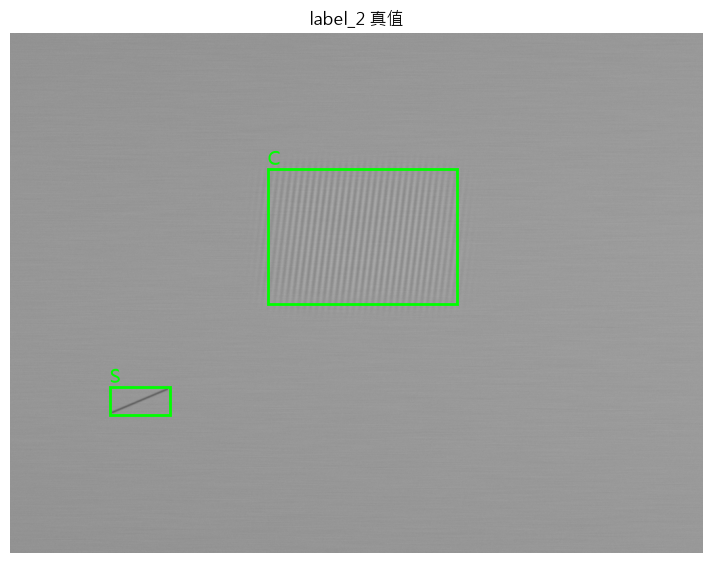

In [5]:
import matplotlib.patches as pa
def show(img, boxes, title, color="lime"):
    w, h = img.size
    fig, ax = plt.subplots(figsize=(9, 6.75)); ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    for c, x, y, bw, bh in boxes:
        ax.add_patch(pa.Rectangle(((x - bw / 2) * w, (y - bh / 2) * h), bw * w, bh * h, fill=False, ec=color, lw=2))
        ax.text((x - bw / 2) * w, (y - bh / 2) * h - 6, CLS[c], color=color, fontsize=14, weight="bold")
    ax.set_title(title); ax.axis("off"); plt.show()
show(img, truth, IMAGE + " 真值")

## 評分：學員的框和真值比

IoU＝兩個框重疊面積 ÷ 聯集面積。用 makesense.ai 標好後匯出 YOLO，把 txt 內容貼到 `MY_BOXES`。

In [6]:
def iou(a, b):
    ax0, ay0, ax1, ay1 = a[1]-a[3]/2, a[2]-a[4]/2, a[1]+a[3]/2, a[2]+a[4]/2
    bx0, by0, bx1, by1 = b[1]-b[3]/2, b[2]-b[4]/2, b[1]+b[3]/2, b[2]+b[4]/2
    iw, ih = max(0, min(ax1, bx1) - max(ax0, bx0)), max(0, min(ay1, by1) - max(ay0, by0))
    inter = iw * ih; return inter / (a[3]*a[4] + b[3]*b[4] - inter)
def score(mine, truth):
    hit, used = [], set()
    for t in truth:
        best = max(((iou(m, t), k) for k, m in enumerate(mine) if k not in used), default=(0, None))
        if best[0] >= IOU_OK:
            used.add(best[1]); hit.append((CLS[t[0]], CLS[mine[best[1]][0]], round(best[0], 2)))
    print("框到 %d／%d；多標 %d 個；類別一致 %d 個" % (len(hit), len(truth), len(mine) - len(used), sum(a == b for a, b, _ in hit)))
    return hit
# 示範：把真值稍微挪動、少框一個、多框一個
MY_BOXES = """2 0.52 0.41 0.27 0.27
3 0.30 0.30 0.05 0.05"""
mine = [(int(a), *map(float, b)) for a, *b in (l.split() for l in MY_BOXES.strip().splitlines())]
score(mine, truth)

框到 1／2；多標 1 個；類別一致 1 個


[('C', 'C', 0.79)]

## 資料增強：哪些還是同一種瑕疵？

原圖是橫向的振紋。振紋的方向和刀具進給方向有關，轉 90 度就不是實物會出現的樣子。

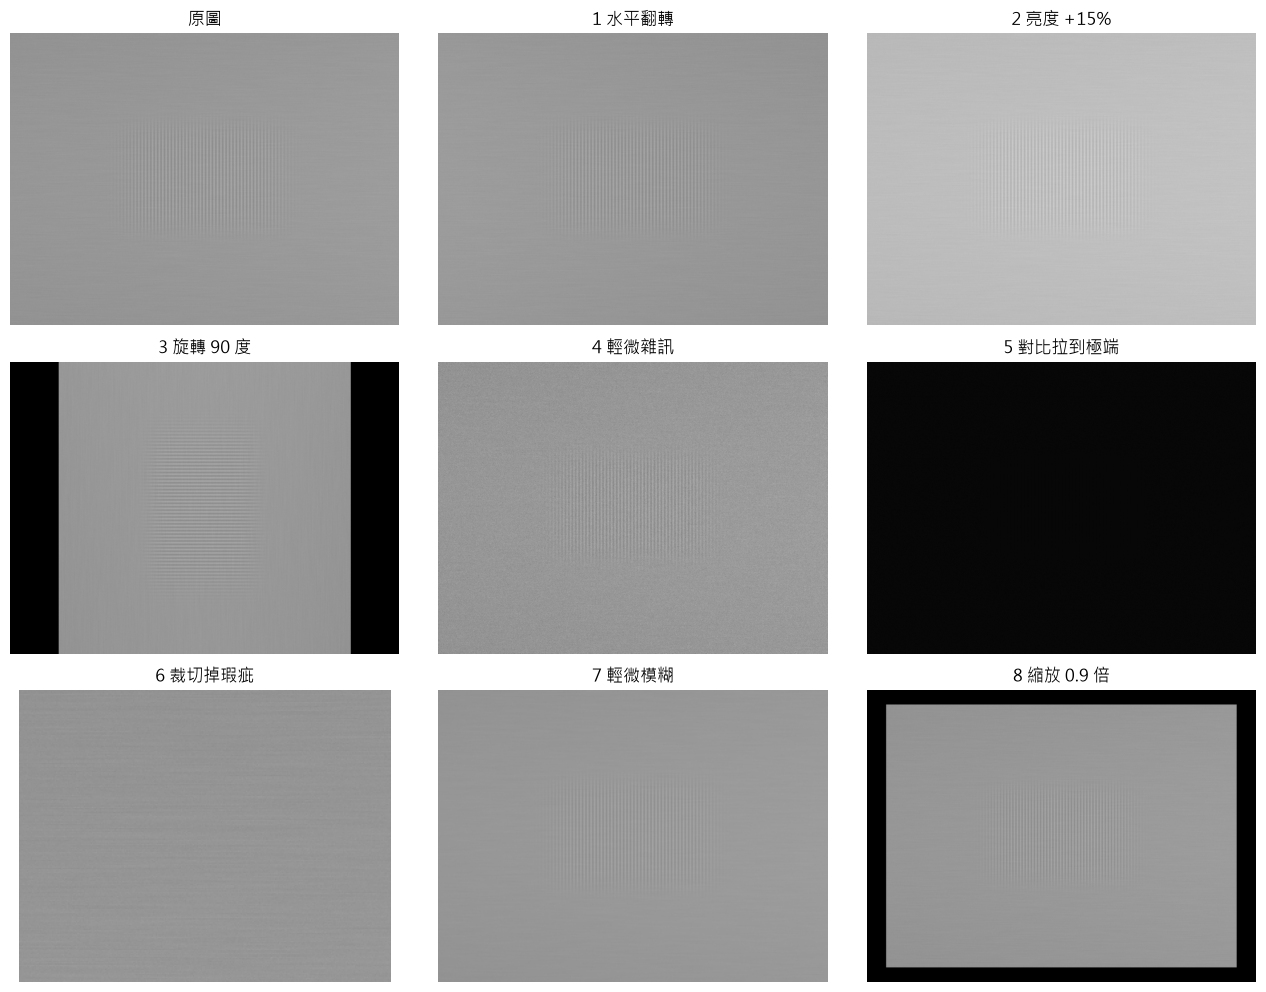

In [7]:
import albumentations as A
src = np.array(load_img("augment_source"))
augs = {
    "1 水平翻轉": A.HorizontalFlip(p=1),
    "2 亮度 +15%": A.RandomBrightnessContrast(brightness_limit=(0.15, 0.15), contrast_limit=(0, 0), p=1),
    "3 旋轉 90 度": A.Rotate(limit=(90, 90), p=1),
    "4 輕微雜訊": A.GaussNoise(std_range=(0.03, 0.03), p=1),
    "5 對比拉到極端": A.RandomBrightnessContrast(brightness_limit=(0, 0), contrast_limit=(-0.95, -0.95), p=1),
    "6 裁切掉瑕疵": A.Crop(x_min=0, y_min=0, x_max=280, y_max=220, p=1),
    "7 輕微模糊": A.GaussianBlur(blur_limit=(5, 5), p=1),
    "8 縮放 0.9 倍": A.Affine(scale=0.9, p=1),
}
fig, ax = plt.subplots(3, 3, figsize=(13, 10)); ax = ax.ravel()
ax[0].imshow(src, cmap="gray", vmin=0, vmax=255); ax[0].set_title("原圖")
for a, (k, t) in zip(ax[1:], augs.items()):
    a.imshow(t(image=src)["image"], cmap="gray", vmin=0, vmax=255); a.set_title(k)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 學員喊參數，現場產生

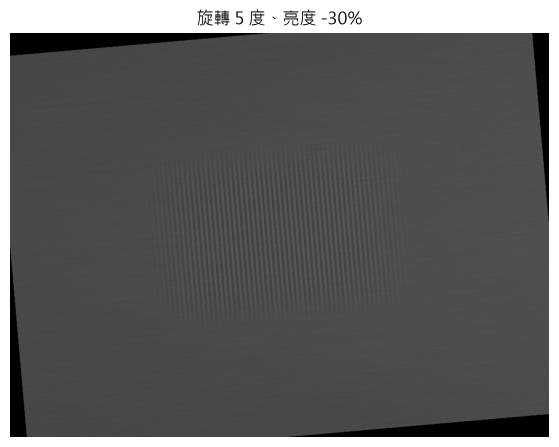

In [8]:
t = A.Compose([A.Rotate(limit=(AUG["rotate"], AUG["rotate"]), p=1),
               A.RandomBrightnessContrast(brightness_limit=(AUG["brightness"], AUG["brightness"]), contrast_limit=(0, 0), p=1)])
plt.figure(figsize=(7, 5.25)); plt.imshow(t(image=src)["image"], cmap="gray", vmin=0, vmax=255)
plt.title("旋轉 %s 度、亮度 %+d%%" % (AUG["rotate"], AUG["brightness"] * 100)); plt.axis("off"); plt.show()